# Prueba Intertrimestral — Solución

**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

Solución de referencia (orientativa). Puede haber variantes válidas.


## Inicialización de librerías


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Ejercicio 1 — Programación (2 puntos)

a) `rental_fee`


In [2]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        base, per_min = 1.00, 0.05
    elif bike_type == "electric":
        base, per_min = 1.50, 0.08
    else:
        raise ValueError(f"bike_type no soportado: {bike_type}")

    total = base + per_min * duration_min
    if is_member:
        total *= 0.80
    return round(total, 2)


assert rental_fee(20, "classic", False) == 2.00
assert rental_fee(20, "classic", True) == 1.60
rental_fee(20, "classic", False)

2.0

b) `demand_label`


In [3]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    if total_rentals >= threshold / 2:
        return "Media"
    return "Baja"


assert demand_label(50, 40) == "Alta"
assert demand_label(25, 40) == "Media"
assert demand_label(10, 40) == "Baja"
demand_label(25, 40)

'Media'

c) DataFrame `tripsDemo`


In [4]:
tripsDemo = pd.DataFrame({
    "duration_min": [10, 15, 20, 25, 30, 12, 40, 8, 18, 22, 35, 14],
    "bike_type": ["classic", "electric", "classic", "electric", "classic",
                  "electric", "classic", "classic", "electric", "classic",
                  "electric", "classic"],
    "is_member": [False, True, True, False, False, True, False, True, False, True, True, False],
    "total_rentals": [12, 45, 28, 60, 33, 22, 71, 9, 41, 38, 55, 19],
})
tripsDemo["fee"] = [
    rental_fee(d, b, m)
    for d, b, m in zip(tripsDemo["duration_min"], tripsDemo["bike_type"], tripsDemo["is_member"])
]
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(lambda x: demand_label(x, 40))
tripsDemo

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,10,classic,False,12,1.50,Baja
1,15,electric,True,45,2.16,Alta
2,20,classic,True,28,1.60,Media
3,25,electric,False,60,3.50,Alta
4,30,classic,False,33,2.50,Media
5,12,electric,True,22,1.97,Media
6,40,classic,False,71,3.00,Alta
7,8,classic,True,9,1.12,Baja
8,18,electric,False,41,2.94,Alta
9,22,classic,True,38,1.68,Media


d) Clase `MicromobilityTools`


In [5]:
class MicromobilityTools:
    def __init__(self, threshold=40):
        self.threshold = threshold

    def fees(self, durations, bike_types, members):
        return [
            rental_fee(d, b, m)
            for d, b, m in zip(durations, bike_types, members)
        ]

    def demands(self, totals):
        return [demand_label(t, self.threshold) for t in totals]


tools = MicromobilityTools(threshold=40)
tools.fees(tripsDemo["duration_min"], tripsDemo["bike_type"], tripsDemo["is_member"])[:3]

[1.5, 2.16, 1.6]

## Ejercicio 2 — Exploración y visualización


In [6]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv", parse_dates=["datetime"])
print(mobilityData.shape)
mobilityData.head()

(17520, 23)


,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,weather,temp_c,humidity,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,Clear,6.39,67.1,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,Clear,4.88,37.2,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,Cloudy,1.72,79.7,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,Clear,-3.40,51.4,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,Cloudy,8.24,82.2,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


b–c) `describeData`


In [7]:
def describeData(dataFrame: pd.DataFrame) -> pd.DataFrame:
    n = len(dataFrame)
    rows = []
    for col in dataFrame.columns:
        nulos = int(dataFrame[col].isna().sum())
        rows.append({
            "column": col,
            "dtype": str(dataFrame[col].dtype),
            "n_null": nulos,
            "pct_null": round(100 * nulos / n, 2) if n else 0.0,
        })
    return pd.DataFrame(rows).sort_values("pct_null", ascending=False)


summary = describeData(mobilityData)
summary.head(10)

,column,dtype,n_null,pct_null
18,avg_trip_min,float64,255,1.46
12,humidity,float64,224,1.28
20,electric_share,float64,182,1.04
13,wind_kmh,float64,142,0.81
0,datetime,datetime64[us],0,0.00
21,revenue_eur,float64,0,0.00
19,avg_distance_km,float64,0,0.00
17,total_rentals,int64,0,0.00
16,member_users,int64,0,0.00
15,casual_users,int64,0,0.00


In [8]:
# Comentario: las columnas con más nulos suelen ser avg_trip_min, humidity,
# electric_share y wind_kmh (del orden del 1%). Antes de modelar conviene
# imputar (mediana) o eliminar esas filas; el impacto es pequeño.
summary[summary["pct_null"] > 0]

,column,dtype,n_null,pct_null
18,avg_trip_min,float64,255,1.46
12,humidity,float64,224,1.28
20,electric_share,float64,182,1.04
13,wind_kmh,float64,142,0.81


d) Visualizaciones


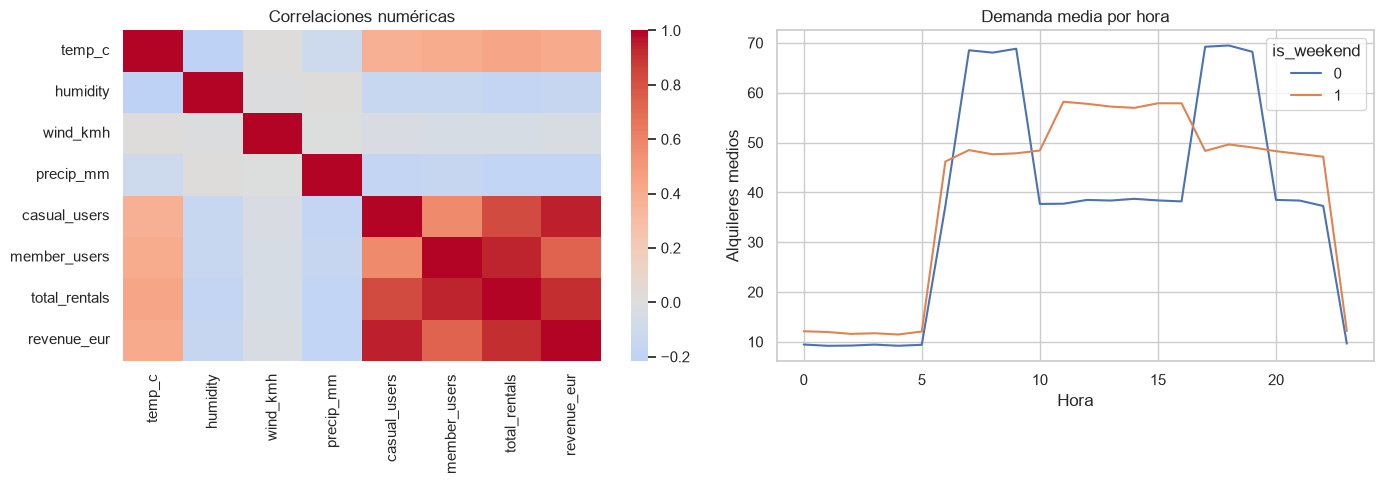

In [9]:
num_cols = [
    "temp_c", "humidity", "wind_kmh", "precip_mm",
    "casual_users", "member_users", "total_rentals", "revenue_eur",
]
corr = mobilityData[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlaciones numéricas")

hourly = (
    mobilityData.groupby(["hour", "is_weekend"], as_index=False)["total_rentals"].mean()
)
sns.lineplot(data=hourly, x="hour", y="total_rentals", hue="is_weekend", ax=axes[1])
axes[1].set_title("Demanda media por hora")
axes[1].set_xlabel("Hora")
axes[1].set_ylabel("Alquileres medios")
plt.tight_layout()
plt.show()

# Hallazgos tipicos: total_rentals correlaciona fuerte con revenue y con member/casual;
# temperatura suele correlacionar positivamente; lluvia/precipitacion negativamente;
# horas punta laborables ~8 y ~18, fines de semana mas repartidos al mediodia.

## Ejercicio 3 — Regresión


In [10]:
targetVar = "total_rentals"
features = ["hour", "temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday", "is_weekend"]

model_df = mobilityData[features + [targetVar]].dropna().copy()
X = model_df[features]
y = model_df[targetVar]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)
X_train.shape, X_test.shape

((12011, 7), (5148, 7))

In [11]:
lin = LinearRegression()
lin.fit(X_train, y_train)
y_pred_lin = lin.predict(X_test)

r2_lin = r2_score(y_test, y_pred_lin)
mse_lin = mean_squared_error(y_test, y_pred_lin)
print(f"LinearRegression  R2={r2_lin:.3f}  MSE={mse_lin:.2f}")

LinearRegression  R2=0.301  MSE=412.59


In [12]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
print(f"RandomForest      R2={r2_rf:.3f}  MSE={mse_rf:.2f}")

# Suele ganar el RandomForest: captura no linealidades (hora punta, umbrales de lluvia, etc.).

RandomForest      R2=0.892  MSE=63.92


## Ejercicio 4 — Clasificación


In [13]:
print(mobilityData["high_demand"].value_counts(normalize=True).round(3))

high_demand
0    0.689
1    0.311
Name: proportion, dtype: float64


Accuracy=0.755


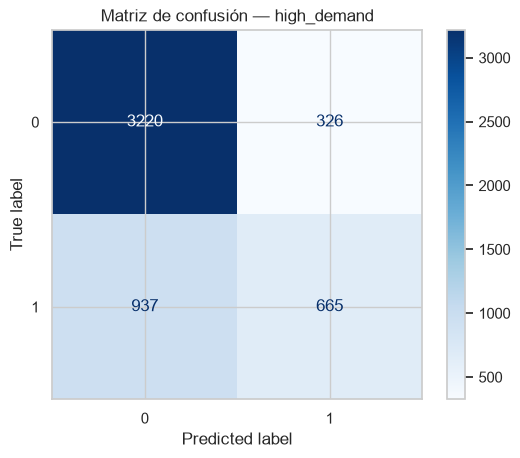

In [14]:
clf_features = ["hour", "temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday", "is_weekend", "is_holiday"]
clf_df = mobilityData[clf_features + ["high_demand"]].dropna().copy()
Xc = clf_df[clf_features]
yc = clf_df["high_demand"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.30, random_state=42, stratify=yc
)

logit = LogisticRegression(max_iter=2000)
logit.fit(Xc_train, yc_train)
yc_pred = logit.predict(Xc_test)

acc = accuracy_score(yc_test, yc_pred)
print(f"Accuracy={acc:.3f}")
cm = confusion_matrix(yc_test, yc_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Matriz de confusión — high_demand")
plt.show()

In [15]:
coef = pd.Series(logit.coef_[0], index=clf_features).sort_values(key=np.abs, ascending=False)
print(coef)

# Interpretacion: hour, is_weekend/is_workingday y precip/temp suelen dominar.
# Coherente con el grafico horario y con el efecto del mal tiempo.

precip_mm       -2.126168
is_weekend       1.331869
is_workingday    0.799637
is_holiday       0.723807
temp_c           0.092501
hour             0.054423
wind_kmh        -0.033531
humidity        -0.016248
dtype: float64


## Ejercicio 5 — Conclusión

La demanda de micromovilidad está muy marcada por la **hora del día** (puntas laborales y ocio en fin de semana), el **tipo de día** y la **meteorología** (mejor con buen tiempo y temperaturas moderadas; peor con lluvia).  

En regresión, el **RandomForest** suele superar a la regresión lineal porque la relación hora–demanda no es lineal. En clasificación, un modelo logístico con contexto temporal y climático separa razonablemente `high_demand`, aunque el desbalance de clases invita a mirar más allá de la accuracy.  

Con más tiempo: features cíclicas de hora, encoding de `weather`/`season`, series temporales, o datos de eventos/precio dinámico mejorarían el modelo.
